# Utils.
- The following modules are provided to help students develop their solutions more easily. You do not need to make any changes to this section.

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import random

def get_binary_image_array(image_path, threshold=0.5):
    """
    Convert an image to a binary NumPy array.

    Args:
        image_path (str): Path to the input image.
        threshold (float): Threshold for binarization (0 to 1 for normalized pixel values).

    Returns:
        numpy.ndarray: Binary image as a NumPy array.
    """
    image = plt.imread(image_path)

    # If the image has an alpha channel (RGBA), ignore it
    if image.shape[-1] == 4:  # Check if it's RGBA
        image = image[:, :, :3]  # Use only RGB channels

    # Convert to grayscale by averaging RGB channels
    grayscale = np.mean(image, axis=2)

    # Convert to binary by applying a threshold
    binary_image = (grayscale > threshold).astype(np.uint8)

    return binary_image


def generate_triangle_edge_template():
    """Generate a binary triangle edge template with diagonal, top row, and right column."""
    h, w = 40, 40  # Height and width of the triangle template
    template = np.zeros((h, w), dtype=np.uint8)  # Start with a black image

    # Set the diagonal pixels
    for i in range(h):
        template[i, i] = 1

    # Set the top row pixels
    template[0, :] = 1

    # Set the right column pixels
    template[:, -1] = 1

    return template

def overlay_template_edges_on_feature(scene, template, match_position):
    """
    Overlay the edges of the template (pixel=1) in red on the feature image.

    Args:
        scene (numpy.ndarray): Binary scene image (grayscale).
        template (numpy.ndarray): Binary template image.
        match_position (tuple): (y, x) position of the best match in the scene.

    Returns:
        numpy.ndarray: RGB feature image with the template edges overlayed in red.
    """
    # Normalize the scene to be in range [0, 255] if necessary
    scene = (scene > 0).astype(np.uint8) * 255  # Ensure binary values are scaled to 255

    # Convert the scene to RGB
    overlay_map = np.stack([scene, scene, scene], axis=-1)  # Grayscale to RGB

    # Extract match position and template dimensions
    y, x = match_position
    th, tw = template.shape

    # Overlay only the edges (pixels with value = 1) of the template in red
    template_edges = (template == 1)  # Binary mask of the edges
    overlay_map[y:y+th, x:x+tw, 0][template_edges] = 255  # Set red channel for edge pixels
    overlay_map[y:y+th, x:x+tw, 1][template_edges] = 0    # Green channel remains 0
    overlay_map[y:y+th, x:x+tw, 2][template_edges] = 0    # Blue channel remains 0

    return overlay_map

# Q4-1 Distance Transform

Implement the module that computes the distance transform using the [Manhattan distance](https://www.datacamp.com/tutorial/manhattan-distance).
You can implement the algorithm in a dynamic programming manner. Implement the forward pass and the backward pass.

HINT : Check the ```ComputerVision-04-Edges&Binary%20Images-1.pdf```, p42 - p45.


```bash
Args:
    binary_image (numpy.ndarray): Binary input image (0 for background, 1 for foreground).
Returns:
    numpy.ndarray: Distance map where each pixel contains the Manhattan distance to the nearest foreground pixel.
```

In [5]:
def distance_transform_manhattan(image_features):

    h, w = image_features.shape
    dist_map = np.full((h, w), np.inf)
    dist_map[image_features == 1] = 0

    ############ANSWER###################
    # Forward pass

    for i in range(h):
        for j in range(w):
            if i > 0:
                dist_map[i, j] = min(dist_map[i, j], dist_map[i - 1, j] + 1)
            if j > 0:
                dist_map[i, j] = min(dist_map[i, j], dist_map[i, j - 1] + 1)

    # Backward pass

    for i in range(h - 1, -1, -1):
        for j in range(w - 1, -1, -1):
            if i < h - 1:
                dist_map[i, j] = min(dist_map[i, j], dist_map[i + 1, j] + 1)
            if j < w - 1:
                dist_map[i, j] = min(dist_map[i, j], dist_map[i, j + 1] + 1)

    ############ANSWER###################

    return dist_map



In [6]:
# Q4-1 answer block # - NO NEED TO CHANGE THIS PART, Run the cell to show the output.
image_features = np.array([
    [0, 0, 0, 1],
    [0, 0, 1, 0],
    [0, 1, 0, 0],
    [1, 0, 0, 0]
], dtype=np.uint8)


# Compute distance maps
dist_map_features = distance_transform_manhattan(image_features)

print("Distance Map for Image Features:")
print(dist_map_features)

Distance Map for Image Features:
[[3. 2. 1. 0.]
 [2. 1. 0. 1.]
 [1. 0. 1. 2.]
 [0. 1. 2. 3.]]


# Q4-2 Chamfer distance matching & Visualization

Using the module ```distance_transform_manhattan``` from Q4-1, implement the chamfer matching algorithm given ```scene(binary image feature)``` and ```template(edge feature)```.

```Chamfer_matching``` should find the template feature in the scene image. By Sliding the template over the scene, compute the chamfer distance using distance transform map. Also, find the best match position based on the generated chamfer map.


```bash
Args:
    scene (numpy.ndarray): Binary scene image.
    template (numpy.ndarray): Binary template image.

Returns:
    Best match position coordinates and Chamfer distance map.

    - best_match_position (tuple): (y, x) position of the best match in the scene.
    - chamfer_map (numpy.ndarray) : Binary chamfer map image
```


HINT : Check the ```ComputerVision-04-Edges&Binary%20Images-1.pdf```, p39-.


In [7]:
# Chamfer distance matching
def chamfer_matching(scene, template):

    #convert the pixel value 0,255 -> 0,1
    scene = (scene > 0).astype(np.uint8)
    # Compute the distance transform of the scene
    dist_transform = distance_transform_manhattan(scene)

    ############ANSWER###################

    th, tw = template.shape
    H, W = scene.shape

    # Coordinates
    ys, xs = np.nonzero(template)

    out_h, out_w = H - th + 1, W - tw + 1
    chamfer_map = np.zeros((out_h, out_w))

    # Slide the template over the scene; chamfer distance is the distance-transform.
    # Value, under the templates edge pixels
    for y in range(out_h):
        for x in range(out_w):
            chamfer_map[y, x] = dist_transform[ys + y, xs + x].mean()

    # Best match = position with the smallest chamfer distance
    best_match_position = np.unravel_index(np.argmin(chamfer_map), chamfer_map.shape)

    ############ANSWER###################

    # Normalize Chamfer map for better visualization
    chamfer_map = (chamfer_map - np.min(chamfer_map)) / (np.max(chamfer_map) - np.min(chamfer_map))

    return best_match_position, chamfer_map

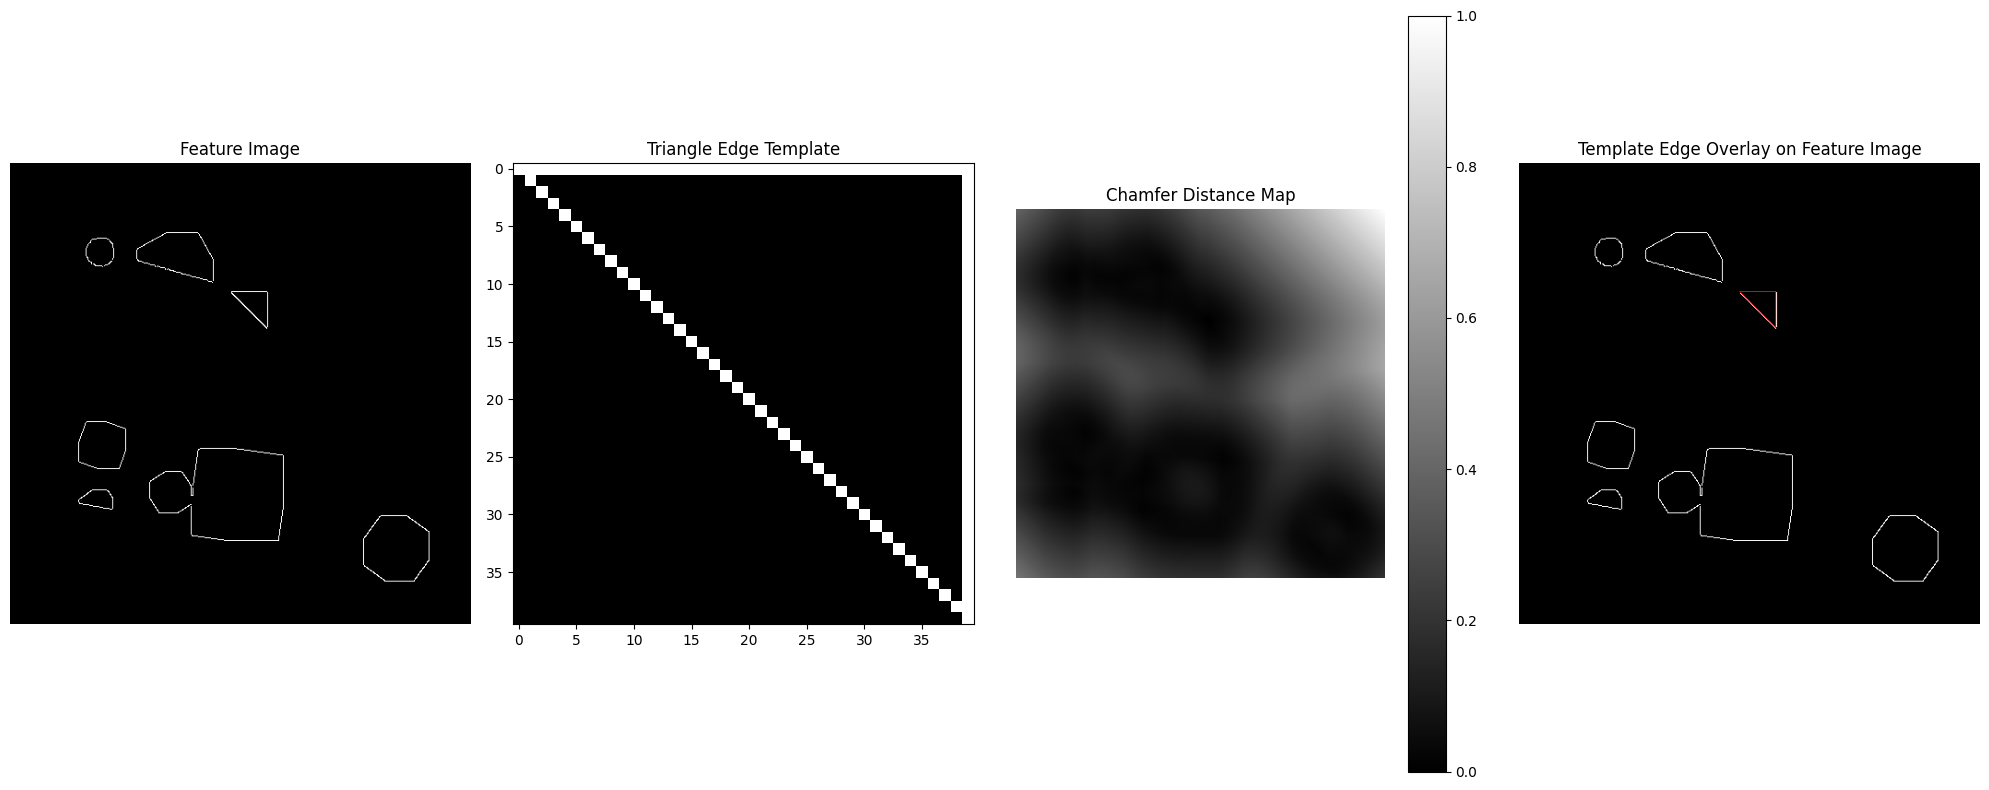

In [8]:
# Q4-2 answer block # - NO NEED TO CHANGE THIS PART, Run the cell to show the output.


"""
The following code provides an example of visualization using the modules from the utils.
You may modify the visualization method as needed,
provided that the results remain consistent with the illustration shown above.
"""

# Load the binary scene image
scene=get_binary_image_array('binary_image.png')
# Detect the edge from the image
scene = cv2.Canny(scene, 0,1)
# Generate the triangle template
template = generate_triangle_edge_template()

# Perform Chamfer matching
best_match_position, chamfer_map = chamfer_matching(scene, template)

# Overlay the edges of the template on the feature image
overlayed_feature_image = overlay_template_edges_on_feature(scene, template, best_match_position)

# Visualization
plt.figure(figsize=(20, 8))

# Feature Image
plt.subplot(1, 4, 1)
plt.title("Feature Image")
plt.imshow(scene, cmap="gray")
plt.axis("off")

# Template
plt.subplot(1, 4, 2)
plt.title("Triangle Edge Template")
plt.imshow(template, cmap="gray")

# Chamfer Distance Map
plt.subplot(1, 4, 3)
plt.title("Chamfer Distance Map")
plt.imshow(chamfer_map, cmap="gray")
plt.colorbar()
plt.axis("off")

# Feature Image with Edge Overlay
plt.subplot(1, 4, 4)
plt.title("Template Edge Overlay on Feature Image")
plt.imshow(overlayed_feature_image)
plt.axis("off")

plt.tight_layout()
plt.show()